# AVIVA | Comparação de classificadores MLP

**Experimento de classificação de chuva intensa com redes neurais.**  
Escopo: comparação controlada de arquiteturas com divisão temporal dos dados.  
ODS relacionados: 11 - Cidades e comunidades sustentaveis; 13 - Acao contra a mudanca global do clima.

## Objetivo
Comparar duas redes `MLPClassifier` para classificar chuva forte no dia seguinte, alterando **somente** o numero de neuronios da camada oculta. O experimento usa a mesma base, divisao temporal e definicao do alvo do notebook de ML tradicional.

> Estudo exploratorio com menos de um ano de dados de duas estacoes. O alvo e chuva forte no dia seguinte, nao previsao de alagamento nem alerta operacional.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

## 1. Dados e preparação

Usamos observacoes dirias das estacoes INMET A701 e A771. As duas primeiras linhas de cada estacao nao tem historico suficiente para as variaveis defasadas. Tambem excluimos dias com mais de seis horas faltantes. As exclusoes so feitas apenas em memoria; o CSV original permanece intacto.

In [2]:
candidatos_csv = [
    Path.cwd() / 'data' / 'processed' / 'aviva_clima_diario.csv',
    Path.cwd().parent / 'data' / 'processed' / 'aviva_clima_diario.csv',
]
caminho_csv = next((p for p in candidatos_csv if p.is_file()), None)
if caminho_csv is None:
    raise FileNotFoundError(
        'Nao encontrei data/processed/aviva_clima_diario.csv. '
        'No Colab, extraia AVIVA_MLP_Colab.zip em /content.'
    )

dados = pd.read_csv(caminho_csv, parse_dates=['data'])
dados = dados.sort_values(['estacao', 'data']).reset_index(drop=True)
colunas_defasadas = [c for c in dados.columns if c.endswith(('_d1', '_d2'))]
dados = dados.loc[dados.groupby('estacao', sort=False).cumcount() >= 2].copy()
assert len(dados) == 600, f'Esperadas 600 linhas apos o corte inicial; obtidas {len(dados)}.'
assert dados[colunas_defasadas].notna().all().all(), 'Ha variaveis defasadas sem historico.'

dias_excluidos = int((dados['horas_faltantes'] > 6).sum())
dados = dados.loc[dados['horas_faltantes'] <= 6].copy()
assert dias_excluidos == 2, f'Esperados 2 dias excludos; obtidos {dias_excluidos}.'
assert len(dados) == 598, f'Esperadas 598 observacoes; obtidas {len(dados)}.'
assert dados['chuva_amanha_mm'].notna().all(), 'Ha alvos ausentes.'

print(f'CSV: {caminho_csv.resolve()}')
print(f'Observaes apos tratamento: {len(dados)}')
print('Observaes por estacao:')
display(dados.groupby('estacao').size().rename('quantidade').to_frame())
print('Resumo das principais variaveis:')
display(dados[['chuva_dia_mm', 'temperatura_media_c', 'umidade_media_pct', 'chuva_amanha_mm']].describe().round(2))

CSV: C:\Users\user\Downloads\AVIVA_v13_Design_Unificado_Desktop_Android\modulos\comunidade\data\processed\aviva_clima_diario.csv
Observaes apos tratamento: 598
Observaes por estacao:


,quantidade
estacao,
A701,298
A771,300


Resumo das principais variaveis:


,chuva_dia_mm,temperatura_media_c,umidade_media_pct,chuva_amanha_mm
count,598.00,598.00,598.00,598.00
mean,5.02,19.61,77.97,5.04
std,10.78,3.19,11.76,10.78
min,0.00,11.08,42.00,0.00
25%,0.00,17.27,69.45,0.00
50%,0.20,19.87,78.56,0.20
75%,3.95,22.15,87.28,4.00
max,74.00,27.33,100.00,74.00


## 2. Alvo e divisao temporal

O alvo binario e `1` quando `chuva_amanha_mm` e maior ou igual ao percentil 90 calculado **somente no treino**. O corte temporal e 21/06/2026: treino antes da data e teste a partir dela. A data e a chuva do dia seguinte sao removidas das entradas do modelo. O teste nao participa do ajuste do limiar nem do pre-processamento.

In [3]:
data_corte = pd.Timestamp('2026-06-21')
treino = dados.loc[dados['data'] < data_corte].copy()
teste = dados.loc[dados['data'] >= data_corte].copy()
assert not treino.empty and not teste.empty
assert treino['data'].max() < teste['data'].min()

alvo_continuo = 'chuva_amanha_mm'
limiar_chuva_forte_mm = float(treino[alvo_continuo].quantile(0.90))
y_treino = (treino[alvo_continuo] >= limiar_chuva_forte_mm).astype(int)
y_teste = (teste[alvo_continuo] >= limiar_chuva_forte_mm).astype(int)
X_treino = treino.drop(columns=['data', alvo_continuo])
X_teste = teste.drop(columns=['data', alvo_continuo])
assert X_treino.columns.tolist() == X_teste.columns.tolist()
assert y_treino.nunique() == 2 and y_teste.nunique() == 2

print(f'Limiar P90 calculado no treino: {limiar_chuva_forte_mm:.2f} mm')
print(f'Treino: {len(treino)} linhas, {treino.data.min().date()} a {treino.data.max().date()}')
print(f'Teste: {len(teste)} linhas, {teste.data.min().date()} a {teste.data.max().date()}')
print('Distribuicao de classes (0 = nao forte, 1 = forte):')
display(pd.DataFrame({'treino': y_treino.value_counts().reindex([0, 1], fill_value=0),
                      'teste': y_teste.value_counts().reindex([0, 1], fill_value=0)}))

Limiar P90 calculado no treino: 16.40 mm
Treino: 338 linhas, 2026-01-03 a 2026-06-20
Teste: 260 linhas, 2026-06-21 a 2026-10-29
Distribuicao de classes (0 = nao forte, 1 = forte):


,treino,teste
chuva_amanha_mm,,
0,303,226
1,35,34


## 3. Comparacao justa: duas configuracoes, um fator diferente

As duas configuracoes mantem iguais funcao de ativacao, otimizador, regularizacao, taxa de aprendizado, maximo de epocas, parada antecipada, divisao dos dados, `random_state` e pre-processamento. **A unica diferenca e `hidden_layer_sizes`:** MLP A tem 16 neuronios em uma camada; MLP B tem 32 neuronios em uma camada.

O `StandardScaler`, a imputacao e a codificacao da estacao estao dentro do `Pipeline`. Chamamos `fit` somente com `X_treino`; portanto, o conjunto de teste nao ajusta as transformacoes. Como ha poucos eventos positivos, calculamos pesos balanceados somente a partir de `y_treino` e aplicamos os mesmos pesos as duas redes. A comparacao no teste e descritiva e nao deve ser usada para ajustar repetidamente hiperparametros. `sample_weight` requer scikit-learn 1.7 ou superior.

In [4]:
colunas_categoricas = ['estacao']
colunas_numericas = [c for c in X_treino.columns if c not in colunas_categoricas]

preprocessador = ColumnTransformer(
    transformers=[
        ('numericas', Pipeline([
            ('imputacao', SimpleImputer(strategy='median')),
            ('escala', StandardScaler()),
        ]), colunas_numericas),
        ('categoricas', Pipeline([
            ('imputacao', SimpleImputer(strategy='most_frequent')),
            ('codificacao', OneHotEncoder(handle_unknown='ignore')),
        ]), colunas_categoricas),
    ]
)

parametros_comuns = {
    'activation': 'relu',
    'solver': 'adam',
    'alpha': 0.001,
    'learning_rate_init': 0.001,
    'max_iter': 1000,
    'early_stopping': True,
    'validation_fraction': 0.15,
    'n_iter_no_change': 30,
    'random_state': 42,
}
configuracoes_mlp = {
    'MLP A 16 neuronios': {**parametros_comuns, 'hidden_layer_sizes': (16,)},
    'MLP B 32 neuronios': {**parametros_comuns, 'hidden_layer_sizes': (32,)},
}
chaves_diferentes = {
    chave for chave in configuracoes_mlp['MLP A 16 neuronios']
    if configuracoes_mlp['MLP A 16 neuronios'][chave]
    != configuracoes_mlp['MLP B 32 neuronios'][chave]
}
assert chaves_diferentes == {'hidden_layer_sizes'}, chaves_diferentes

display(pd.DataFrame(configuracoes_mlp).T)

,activation,solver,alpha,learning_rate_init,max_iter,early_stopping,validation_fraction,n_iter_no_change,random_state,hidden_layer_sizes
MLP A 16 neuronios,relu,adam,0.001,0.001,1000,True,0.15,30,42,"(16,)"
MLP B 32 neuronios,relu,adam,0.001,0.001,1000,True,0.15,30,42,"(32,)"


In [5]:
modelos_mlp = {}
metricas = []
previsoes = {}
probabilidades = {}
matrizes = {}
pesos_treino = compute_sample_weight(class_weight='balanced', y=y_treino)
print('Pesos balanceados calculados apenas com as classes do treino.')

for nome, parametros in configuracoes_mlp.items():
    modelo = Pipeline([
        ('preprocessamento', preprocessador),
        ('classificador', MLPClassifier(**parametros)),
    ])
    modelo.fit(X_treino, y_treino, classificador__sample_weight=pesos_treino)
    classe_prevista = modelo.predict(X_teste)
    probabilidade_forte = modelo.predict_proba(X_teste)[:, 1]
    classificador = modelo.named_steps['classificador']

    modelos_mlp[nome] = modelo
    previsoes[nome] = pd.Series(classe_prevista, index=X_teste.index)
    probabilidades[nome] = pd.Series(probabilidade_forte, index=X_teste.index)
    matrizes[nome] = confusion_matrix(y_teste, classe_prevista, labels=[0, 1])
    metricas.append({
        'modelo': nome,
        'accuracy': accuracy_score(y_teste, classe_prevista),
        'precisao': precision_score(y_teste, classe_prevista, zero_division=0),
        'recall': recall_score(y_teste, classe_prevista, zero_division=0),
        'F1': f1_score(y_teste, classe_prevista, zero_division=0),
        'ROC-AUC': roc_auc_score(y_teste, probabilidade_forte),
        'acuracia balanceada': balanced_accuracy_score(y_teste, classe_prevista),
        'positivos previstos': int((classe_prevista == 1).sum()),
        'falsos positivos': int(((y_teste.to_numpy() == 0) & (classe_prevista == 1)).sum()),
        'falsos negativos': int(((y_teste.to_numpy() == 1) & (classe_prevista == 0)).sum()),
        'iteracoes': classificador.n_iter_,
        'loss final': classificador.loss_,
    })

metricas = pd.DataFrame(metricas).set_index('modelo')
print('Metricas no conjunto de teste:')
display(metricas.round(3))

# Verifica que o scaler foi ajustado nos valores imputados do treino, nunca no teste.
for nome, modelo in modelos_mlp.items():
    pipeline_numerico = modelo.named_steps['preprocessamento'].named_transformers_['numericas']
    dados_treino_imputados = pipeline_numerico.named_steps['imputacao'].transform(X_treino[colunas_numericas])
    scaler = pipeline_numerico.named_steps['escala']
    np.testing.assert_allclose(scaler.mean_, dados_treino_imputados.mean(axis=0), rtol=1e-7, atol=1e-7)
print('Verificacao: StandardScaler ajustado somente nas entradas de treino.')

Pesos balanceados calculados apenas com as classes do treino.


Metricas no conjunto de teste:


,accuracy,precisao,recall,F1,ROC-AUC,acuracia balanceada,positivos previstos,falsos positivos,falsos negativos,iteracoes,loss final
modelo,,,,,,,,,,,
MLP A 16 neuronios,0.808,0.136,0.088,0.107,0.571,0.502,22,19,31,123,0.448
MLP B 32 neuronios,0.192,0.139,1.000,0.245,0.541,0.535,244,210,0,33,0.611


Verificacao: StandardScaler ajustado somente nas entradas de treino.


## 4. Matrizes de confusao

As linhas representam a classe real e as colunas, a classe prevista. A classe positiva (1) significa chuva forte no dia seguinte. Um falso negativo e um evento forte que a rede nao identificou; a taxa de falsos negativos deve ser considerada junto com precisao e F1.

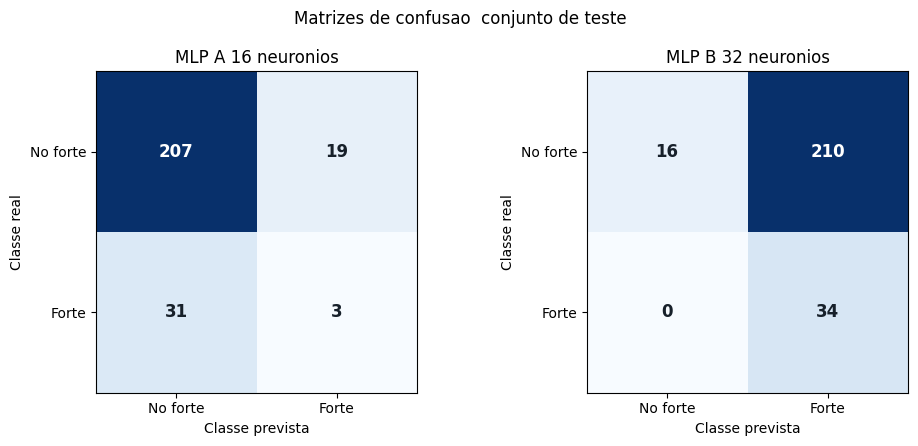

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (nome, matriz) in zip(eixos, matrizes.items()):
    ax.imshow(matriz, cmap='Blues')
    ax.set_title(nome)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
    ax.set_xticks([0, 1], labels=['No forte', 'Forte'])
    ax.set_yticks([0, 1], labels=['No forte', 'Forte'])
    limite = matriz.max() / 2
    for linha in range(2):
        for coluna in range(2):
            ax.text(coluna, linha, str(matriz[linha, coluna]), ha='center', va='center',
                    color='white' if matriz[linha, coluna] > limite else '#17202A',
                    fontsize=12, fontweight='bold')
fig.suptitle('Matrizes de confusao  conjunto de teste')
fig.tight_layout()
plt.show()

## 5. Curvas de perda durante o treinamento

`loss_curve_` mostra a funcao de perda no treinamento. Uma curva menor ou decrescente nao garante generalizacao: a conclusao tambem depende das metricas e dos erros no periodo de teste separado.

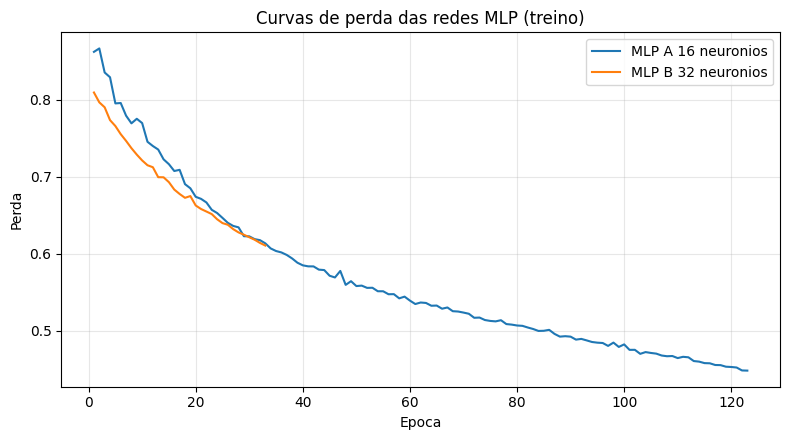

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, modelo in modelos_mlp.items():
    classificador = modelo.named_steps['classificador']
    ax.plot(np.arange(1, len(classificador.loss_curve_) + 1), classificador.loss_curve_, label=nome)
ax.set(title='Curvas de perda das redes MLP (treino)', xlabel='Epoca', ylabel='Perda')
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 6. Comparacao ROC

A curva ROC compara a taxa de verdadeiros positivos e falsos positivos em varios limiares. AUC maior indica melhor ordenacao dos casos, mas nao garante boa classificacao no limiar padrao de 0,5 nem substitui F1/recall.

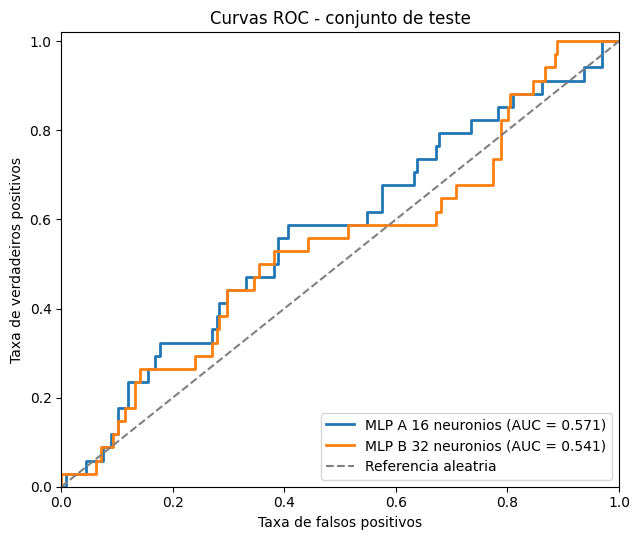

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nome, probabilidade in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_teste, probabilidade)
    auc = roc_auc_score(y_teste, probabilidade)
    ax.plot(fpr, tpr, linewidth=2, label=f'{nome} (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Referencia aleatria')
ax.set(title='Curvas ROC - conjunto de teste', xlabel='Taxa de falsos positivos',
       ylabel='Taxa de verdadeiros positivos', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

## 7. Previsoes em observacoes do teste

Exibimos seis observacoes do teste: tres de cada classe real, escolhidas de forma deterministica. A tabela inclui atributos de entrada, chuva observada, classe prevista e probabilidade estimada. A amostra serve para explicar previsoes e nao altera as metricas nem o treinamento.

In [9]:
indices_exemplos = []
for classe in (0, 1):
    candidatos = y_teste.index[y_teste == classe]
    quantidade = min(3, len(candidatos))
    escolhidos = pd.Series(candidatos).sample(n=quantidade, random_state=42).tolist()
    indices_exemplos.extend(escolhidos)
indices_exemplos = sorted(indices_exemplos, key=lambda idx: (teste.loc[idx, 'data'], teste.loc[idx, 'estacao']))

nome_rede_referencia = metricas['F1'].idxmax()
exemplos = X_teste.loc[indices_exemplos, ['estacao', 'chuva_dia_mm', 'temperatura_media_c', 'umidade_media_pct']].copy()
exemplos.insert(0, 'data', teste.loc[indices_exemplos, 'data'].dt.date.astype(str))
exemplos['chuva_amanha_observada_mm'] = teste.loc[indices_exemplos, alvo_continuo]
exemplos['classe_real'] = y_teste.loc[indices_exemplos]
exemplos['classe_prevista_MLP_A'] = previsoes['MLP A 16 neuronios'].loc[indices_exemplos]
exemplos['classe_prevista_MLP_B'] = previsoes['MLP B 32 neuronios'].loc[indices_exemplos]
exemplos[f'probabilidade_forte_{nome_rede_referencia}'] = probabilidades[nome_rede_referencia].loc[indices_exemplos]
print(f'Exemplos do teste; probabilidade exibida para a rede de maior F1: {nome_rede_referencia}')
display(exemplos.round(3))

Exemplos do teste; probabilidade exibida para a rede de maior F1: MLP B 32 neuronios


,data,estacao,chuva_dia_mm,temperatura_media_c,umidade_media_pct,chuva_amanha_observada_mm,classe_real,classe_prevista_MLP_A,classe_prevista_MLP_B,probabilidade_forte_MLP B 32 neuronios
475,2026-06-23,A771,55.2,16.454,85.750,21.0,1,0,1,0.868
182,2026-07-02,A701,0.0,21.214,59.091,0.0,0,0,1,0.816
484,2026-07-02,A771,0.0,20.179,75.458,0.2,0,0,1,0.538
551,2026-09-07,A771,2.0,11.517,96.500,0.0,0,0,1,0.800
565,2026-09-21,A771,0.4,23.633,71.708,35.2,1,0,1,0.585
295,2026-10-23,A701,10.8,19.721,80.583,24.8,1,0,1,0.581


## 8. Conclusao e limitacoes

Compare A e B considerando principalmente F1, recall, matrizes de confusao, falsos positivos e ROC-AUC; nao escolha somente pela acuracia. O balanceamento e calculado apenas no treino e pode aumentar a deteccao de positivos ao custo de mais falsos alarmes. A decisao abaixo e somente exploratoria: nenhum dos modelos deve ser usado operacionalmente sem novos dados, validacao e avaliacao de custos.

Ha apenas 598 observacoes de duas estacoes, treino e teste pertencem a periodos sazonais diferentes e existem poucos positivos. Os resultados nao demonstram generalizacao. O alvo e chuva forte no dia seguinte, nao previsao de alagamentos; o experimento nao deve emitir alertas reais.

### Roteiro para video (ate 5 minutos)
1. Apresente equipe/RMs, objetivo e ODS.
2. Explique base, alvo P90 e corte temporal.
3. Mostre que A/B diferem apenas por 16 versus 32 neuronios e que o scaler ajusta somente no treino.
4. Compare metricas, matrizes e curvas de perda/ROC.
5. Interprete as seis previsoes, incluindo erros, falsos positivos e falsos negativos.
6. Feche com a escolha exploratoria e as limitacoes.

In [10]:
modelo_escolhido = metricas['F1'].idxmax()
linha_escolhida = metricas.loc[modelo_escolhido]
print(f'Escolha exploratoria pelo maior F1: {modelo_escolhido} (F1={linha_escolhida["F1"]:.3f}, recall={linha_escolhida["recall"]:.3f}).')
print(f'Limite observado: {int(linha_escolhida["falsos positivos"])} falsos positivos no teste, entre {int((y_teste == 0).sum())} dias sem chuva forte.')
print('Essa escolha nao representa prontidao operacional; os falsos alarmes e a pequena amostra exigem validacao adicional.')

Escolha exploratoria pelo maior F1: MLP B 32 neuronios (F1=0.245, recall=1.000).
Limite observado: 210 falsos positivos no teste, entre 226 dias sem chuva forte.
Essa escolha nao representa prontidao operacional; os falsos alarmes e a pequena amostra exigem validacao adicional.


In [11]:
# Exporta visualizações para documentação e análise dos modelos.
raiz_saida = next(
    (pai for pai in [caminho_csv.parent, *caminho_csv.parents] if (pai / 'ENTREGAS_FIAP').is_dir()),
    Path.cwd(),
)
if (raiz_saida / 'ENTREGAS_FIAP').is_dir():
    pasta_graficos = raiz_saida / 'ENTREGAS_FIAP' / '05_MLP' / 'graficos'
else:
    pasta_graficos = Path.cwd() / 'graficos_mlp'
pasta_graficos.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, modelo in modelos_mlp.items():
    perda = modelo.named_steps['classificador'].loss_curve_
    ax.plot(np.arange(1, len(perda) + 1), perda, label=nome)
ax.set(title='Curvas de perda das redes MLP (treino)', xlabel='Epoca', ylabel='Perda')
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(pasta_graficos / '01_curvas_perda.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, eixos = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (nome, matriz) in zip(eixos, matrizes.items()):
    ax.imshow(matriz, cmap='Blues')
    ax.set_title(nome)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
    ax.set_xticks([0, 1], labels=['Nao forte', 'Forte'])
    ax.set_yticks([0, 1], labels=['Nao forte', 'Forte'])
    limite = matriz.max() / 2
    for linha in range(2):
        for coluna in range(2):
            ax.text(coluna, linha, str(matriz[linha, coluna]), ha='center', va='center',
                    color='white' if matriz[linha, coluna] > limite else '#17202A',
                    fontsize=12, fontweight='bold')
fig.suptitle('Matrizes de confusao - conjunto de teste')
fig.tight_layout()
fig.savefig(pasta_graficos / '02_matrizes_confusao.png', dpi=180, bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nome, probabilidade in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_teste, probabilidade)
    auc = roc_auc_score(y_teste, probabilidade)
    ax.plot(fpr, tpr, linewidth=2, label=f'{nome} (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Referencia aleatoria')
ax.set(title='Curvas ROC - conjunto de teste', xlabel='Taxa de falsos positivos',
       ylabel='Taxa de verdadeiros positivos', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(pasta_graficos / '03_curvas_roc.png', dpi=180, bbox_inches='tight')
plt.close(fig)

print('Graficos salvos em:', pasta_graficos.resolve())
print('Arquivos:', ', '.join(sorted(p.name for p in pasta_graficos.glob('*.png'))))

Graficos salvos em: C:\Users\user\Downloads\AVIVA_v13_Design_Unificado_Desktop_Android\ENTREGAS_FIAP\05_MLP\graficos
Arquivos: 01_curvas_perda.png, 02_matrizes_confusao.png, 03_curvas_roc.png
